In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from scipy import stats
import os

In [44]:
df = pd.read_csv('../data/regime_change/bm_n1800_GenBIN_Fr0.500_mpri3.000_spri0.200_msec5.300_ssec0.600_WarmA0.760_c200_w_1300.csv')
df.head(10)

,x
0,9.730022
1,3.735150
2,4.030418
3,3.934332
4,3.939249
5,8.729674
6,9.459832
7,9.416173
8,3.606871
9,3.542178


In [45]:
df.shape

(1800, 1)

In [46]:
df.describe

<bound method NDFrame.describe of              x
0     9.730022
1     3.735150
2     4.030418
3     3.934332
4     3.939249
...        ...
1795  7.923218
1796  2.809317
1797  8.287811
1798  8.176333
1799  3.158119

[1800 rows x 1 columns]>

In [47]:
df.info

<bound method DataFrame.info of              x
0     9.730022
1     3.735150
2     4.030418
3     3.934332
4     3.939249
...        ...
1795  7.923218
1796  2.809317
1797  8.287811
1798  8.176333
1799  3.158119

[1800 rows x 1 columns]>

## Box Plots

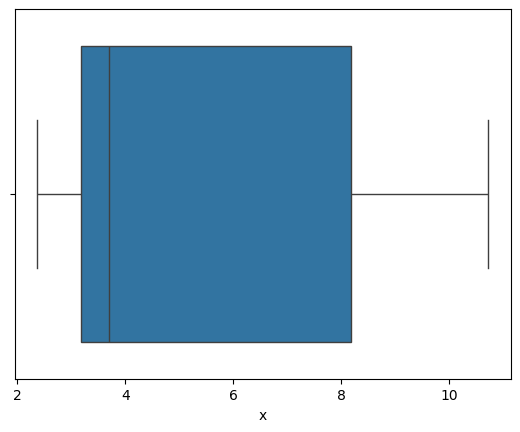

In [48]:
for i in df.select_dtypes(include="number").columns:
    sns.boxplot(data=df, x=i)
    plt.show

In [49]:
scale = StandardScaler()
df_scaled = pd.DataFrame(scale.fit_transform(df), columns=df.columns, index=df.index)
df_scaled

,x
0,1.816986
1,-0.548850
2,-0.432325
3,-0.470245
4,-0.468304
...,...
1795,1.103943
1796,-0.914224
1797,1.247827
1798,1.203833


## Missing Values Checking

In [50]:
df.isna().sum()
df.isna().mean() * 100

x    0.0
dtype: float64

## Histogram aNd Kernel Density Estimation Plots

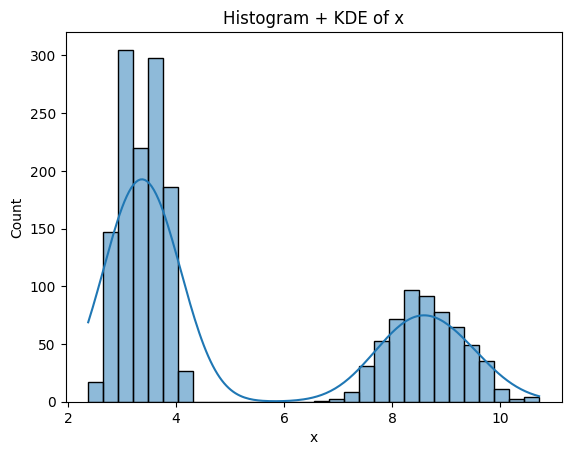

In [51]:
col = df.columns[0]

sns.histplot(df[col], kde=True, bins=30)
plt.title("Histogram + KDE of " + col)
plt.show()

## Time Series Plot

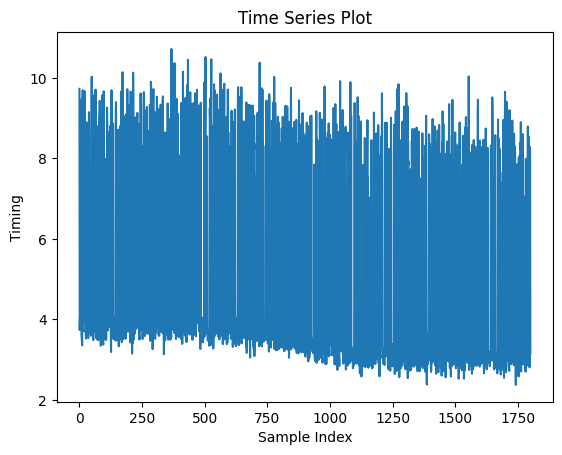

In [52]:
col = df.columns[0]

plt.plot(df[col])
plt.title("Time Series Plot")
plt.xlabel("Sample Index")
plt.ylabel("Timing")
plt.show()

## Detecting Convergence Through Roling Mean

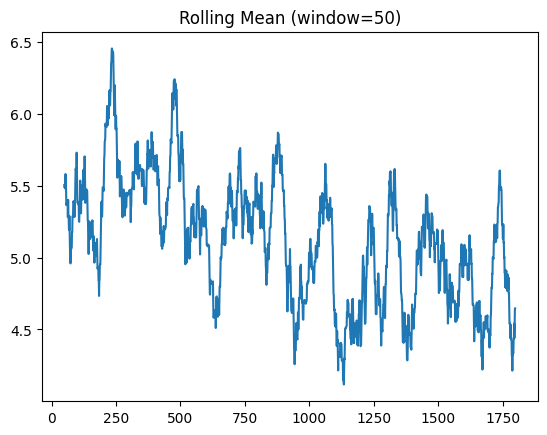

In [53]:
df['roll_mean_50'] = df[col].rolling(window=50).mean()
plt.plot(df['roll_mean_50'])
plt.title("Rolling Mean (window=50)")
plt.show()

## Rolling Varriance

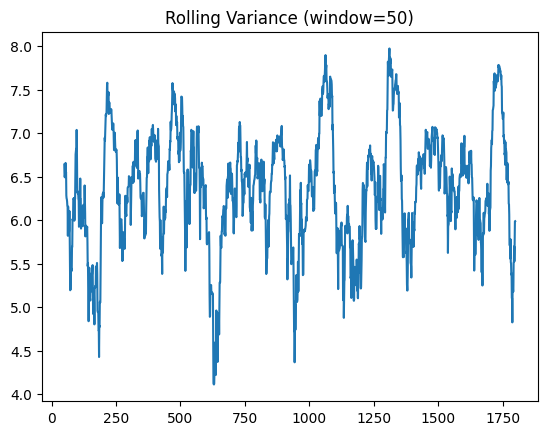

In [54]:
df['rollingVariance'] = df[col].rolling(window=50).var()
plt.plot(df['rollingVariance'])
plt.title("Rolling Variance (window=50)")
plt.show()

## 1st Order Derivative/Fluctuations

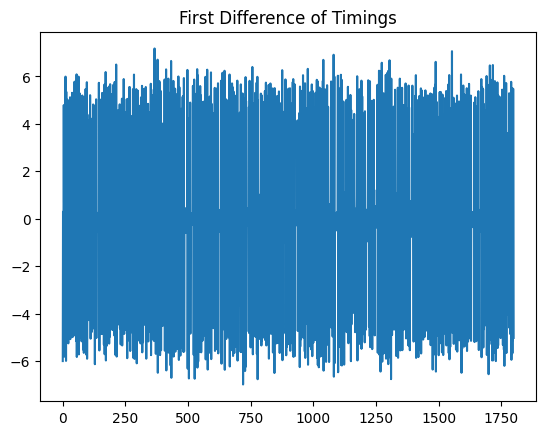

In [55]:
df['diff'] = df[col].diff()
plt.plot(df['diff'])
plt.title("First Difference of Timings")
plt.show()

## QQ Plot

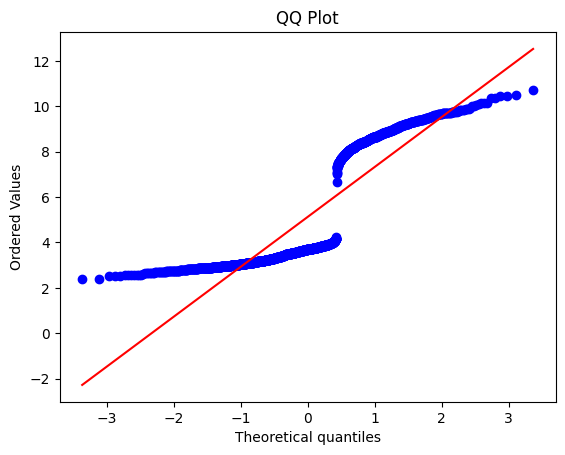

In [56]:
stats.probplot(df[col], dist="norm", plot=plt)
plt.title("QQ Plot")
plt.show()

## Skewn + Kurtosis

In [57]:
df[col].skew(), df[col].kurt()

(np.float64(0.7342164546973784), np.float64(-1.2919905711543502))

## Inter Quartile Range for Outlier Detection

In [58]:
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outliers = df[(df[col] < lower) | (df[col] > upper)]
outliers.head(), len(outliers)

(Empty DataFrame
 Columns: [x, roll_mean_50, rollingVariance, diff]
 Index: [],
 0)